# Exact random-link welfare benchmark

Each directed sponsorship is independent with probability $p$. Access edges have probability $q=1-(1-p)^2$. The library evaluates the exact breadth-first-search recursion from `temp/random-link-benchmark.tex`, with disconnected pairs contributing zero. Expected mean welfare is $(n-1)(\lambda\,\mathbb{E}[\delta^D]-p)$.

Calibration uses **1,000 equally spaced probabilities** on $[0,\min(1,\lambda\delta)]$, including both endpoints. The expectation is exact up to floating-point arithmetic; the reported maximum is a grid estimate. The parameter maps share a grid on $[0,1]$, as in the manuscript, so their discretization differs slightly from calibration.

The recursion costs $O(n^3)$ per probability and discount. Population sweeps are limited to selected sizes up to 100; maps evaluate all discounts together and reuse distances across benefit-to-cost ratios. Hatched map regions have nonpositive star welfare, where normalization is undefined.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib_inline.backend_inline import set_matplotlib_formats

from network_creation.stats.topology_welfare import (
    er_centered_mean_welfare,
    er_discounted_distance_expectation,
    max_er_centered_mean_welfare,
    reference_centered_mean_welfare,
)

%matplotlib inline
plt.style.use(["science", "no-latex"])
set_matplotlib_formats("svg")
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 17,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 13,
    "figure.titlesize": 19,
})

welfare_cmap = LinearSegmentedColormap.from_list(
    "welfare_blues", ("#eaf2f8", "#1f4e79")
)

grid_points = 1000
parameter_points = 64
population_sizes = (10, 50, 100)

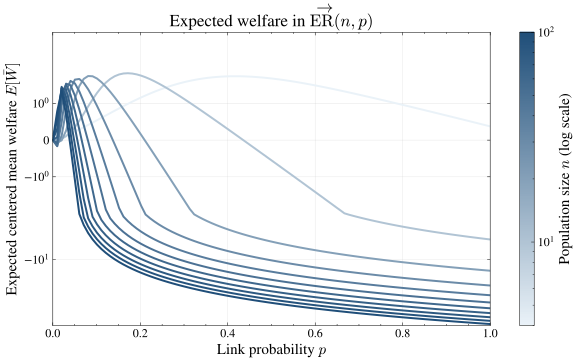

In [2]:
n_values = np.array([4, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100], dtype=int)
p_values = np.linspace(0, 1, 100, dtype=np.float64)

results = np.zeros((len(n_values), len(p_values)), dtype=np.float64)
for i, n in enumerate(n_values):
    for j, p in enumerate(p_values):
        results[i, j] = er_centered_mean_welfare(
            n_agents=int(n),
            benefit_to_cost_ratio=10 / (2 * n),
            directed_link_probability=float(p),
            distance_discount=0.9,
        )

figure, axis = plt.subplots(figsize=(8, 5), layout="compressed")

norm = LogNorm(vmin=n_values.min(), vmax=n_values.max())

for i, n in enumerate(n_values):
    axis.plot(
        p_values,
        results[i],
        color=welfare_cmap(norm(n)),
        linewidth=2,
    )

axis.set_title(r"Expected welfare in $\overrightarrow{\mathrm{ER}}(n,p)$")
axis.set_xlabel(r"Link probability $p$")
axis.set_ylabel(r"Expected centered mean welfare $E[\bar W]$")
axis.set_xlim(0, 1)
axis.set_yscale("symlog")
axis.grid(alpha=0.3)

scalar_mappable = plt.cm.ScalarMappable(cmap=welfare_cmap, norm=norm)
figure.colorbar(
    scalar_mappable,
    ax=axis,
    label=r"Population size $n$ (log scale)",
)

plt.show()

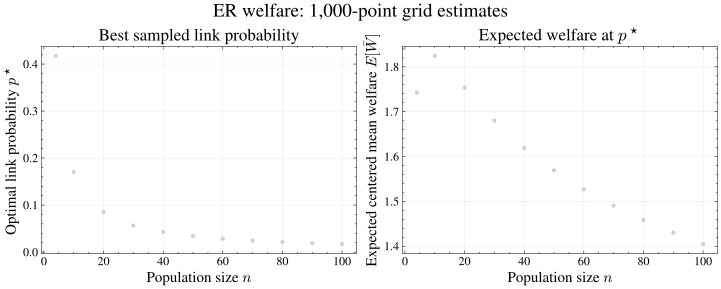

In [3]:
best_p_values = np.empty(len(n_values), dtype=np.float64)
best_welfare_values = np.empty(len(n_values), dtype=np.float64)
for i, n in enumerate(n_values):
    benefit_ratio = 5.0 / n
    probabilities = np.linspace(0.0, min(1.0, benefit_ratio * 0.9), grid_points)
    candidate_welfare = np.array([
        er_centered_mean_welfare(
            n_agents=int(n),
            benefit_to_cost_ratio=benefit_ratio,
            distance_discount=0.9,
            directed_link_probability=float(probability),
        )
        for probability in probabilities
    ])
    best = int(np.argmax(candidate_welfare))
    best_p_values[i] = probabilities[best]
    best_welfare_values[i] = candidate_welfare[best]

figure, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
    sharex=True,
    layout="compressed",
)

axes[0].scatter(
    n_values,
    best_p_values,
    color="#1f4e79",
    marker="o",
    s=10,
    alpha=0.2
)
axes[0].set_title("Best sampled link probability")
axes[0].set_xlabel(r"Population size $n$")
axes[0].set_ylabel(r"Optimal link probability $p^\star$")
axes[0].grid(alpha=0.3)

axes[1].scatter(
    n_values,
    best_welfare_values,
    color="#1f4e79",
    marker="o",
    s=10,
    alpha=0.2
)
axes[1].set_title(r"Expected welfare at $p^\star$")
axes[1].set_xlabel(r"Population size $n$")
axes[1].set_ylabel(r"Expected centered mean welfare $E[\bar W]$")
axes[1].grid(alpha=0.3)

figure.suptitle(f"ER welfare: {grid_points:,}-point grid estimates")
plt.show()

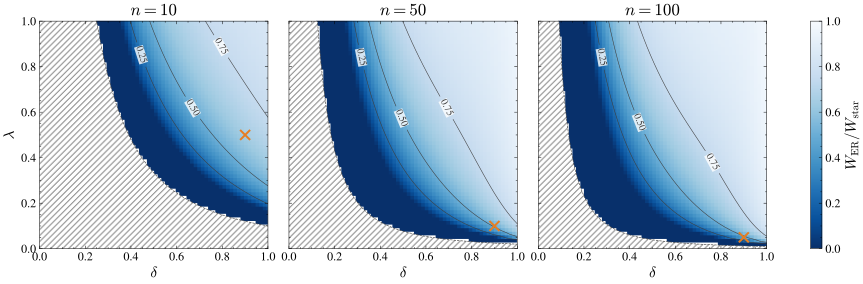

In [4]:
benefit_to_cost_ratio_values = np.linspace(0.0, 1.0, parameter_points)
distance_discount_values = np.linspace(0.0, 1.0, parameter_points)
map_probabilities = np.linspace(0.0, 1.0, grid_points)
welfare_ratios = {}

for n in population_sizes:
    # Shape (probability, discount); independent of the benefit-to-cost ratio.
    expectations = np.array([
        er_discounted_distance_expectation(n, float(p), distance_discount_values)
        for p in map_probabilities
    ])
    er_payoff = (n - 1) * np.max(
        benefit_to_cost_ratio_values[:, None, None] * expectations[None, :, :]
        - map_probabilities[None, :, None],
        axis=1,
    )
    star_payoff = ((n - 1) / n) * (
        benefit_to_cost_ratio_values[:, None]
        * (2 * distance_discount_values + (n - 2) * distance_discount_values**2)
        - 1
    )
    welfare_ratios[n] = np.divide(
        er_payoff, star_payoff,
        out=np.full_like(star_payoff, np.nan), where=star_payoff > 0,
    )

figure, axes = plt.subplots(
    1,
    len(population_sizes),
    figsize=(12, 4),
    sharex=True,
    sharey=True,
    layout="compressed",
)

for axis, n in zip(axes, population_sizes):
    efficiency = np.ma.masked_invalid(welfare_ratios[n])
    image = axis.pcolormesh(
        distance_discount_values, benefit_to_cost_ratio_values,
        efficiency,
        shading="nearest",
        rasterized=True,
        cmap="Blues_r",
        vmin=0.0,
        vmax=1.0,
    )
    contours = axis.contour(
        distance_discount_values, benefit_to_cost_ratio_values, efficiency,
        levels=[0.25, 0.5, 0.75], colors="#3d3d3d", linewidths=0.55,
    )
    labels = axis.clabel(contours, fmt="%.2f", inline=True, fontsize=10)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 0.15})
    boundary_delta = np.linspace(0.0, 1.0, 1000)
    denominator = 2 * boundary_delta + (n - 2) * boundary_delta**2
    boundary = np.divide(
        1, denominator, out=np.full_like(denominator, np.inf), where=denominator > 0,
    )
    axis.fill_between(
        boundary_delta, 0, np.minimum(boundary, 1),
        facecolor="white", edgecolor="#888888", hatch="////", linewidth=0,
    )
    axis.plot(boundary_delta, boundary, "--", color="#444444", linewidth=0.65)
    axis.set_title(rf"$n = {n}$")
    axis.set_xlabel(r"$\delta$")
    axis.set_box_aspect(1)
    axis.set(xlim=(0, 1), ylim=(0, 1))
    axis.plot(
        0.9,
        10 / (2 * n),
        marker="x",
        color="#e67e22",
        markersize=10,
        markeredgewidth=2,
    )

axes[0].set_ylabel(r"$\lambda$")
figure.colorbar(
    image,
    ax=axes,
    label=r"$W_{\mathrm{ER}}/W_{\mathrm{star}}$",
)
plt.show()

In [5]:
distance_discount = 0.9
print("  n       p*      normalized welfare")
for N in population_sizes:
    benefit_to_cost_ratio = 10 / (2 * N)
    max_welfare_reference = reference_centered_mean_welfare(
        reference="max",
        n_agents=N,
        benefit_to_cost_ratio=benefit_to_cost_ratio,
        distance_discount=distance_discount,
    )
    er_welfare_reference = max_er_centered_mean_welfare(
        n_agents=N,
        benefit_to_cost_ratio=benefit_to_cost_ratio,
        distance_discount=distance_discount,
        grid_points=grid_points,
    )
    index = int(np.flatnonzero(n_values == N)[0])
    assert np.isclose(er_welfare_reference, best_welfare_values[index])
    print(
        f"{N:3d}   {best_p_values[index]:.4f}      "
        f"{er_welfare_reference / max_welfare_reference:.3f}"
    )

  n       p*      normalized welfare
 10   0.1707      0.646


 50   0.0339      0.522


100   0.0171      0.464
